In [3]:
import numpy as np
from pathlib import Path
from numpy.lib.format import open_memmap
from scipy import linalg
import matplotlib.pyplot as plt
from aotools.turbulence.infinitephasescreen import PhaseScreenVonKarman, PhaseScreenKolmogorov
%matplotlib qt

def make_vk_screen_robust(
    nx_size: int,
    pupil_diam_m: float,
    r0_m: float,
    L0_m: float,
    random_seed: int = 42,
    oversize: float = 1.0,
    max_halves_L0: int = 3,
    max_oversize_steps: int = 2,
    verbose: bool = True,
):
    """
    Returns (screen_obj, pixel_scale_m, model_name)
      model_name ∈ {"vonKarman", "kolmogorov"}
    """
    D_sim = pupil_diam_m * oversize

    for _ in range(max_oversize_steps + 1):
        pixel_scale = D_sim / nx_size
        L0_try = L0_m

        for _ in range(max_halves_L0 + 1):
            try:
                if verbose:
                    print(f"[VK try] nx={nx_size}, px={pixel_scale:.3e} m, r0={r0_m:.3f} m, L0={L0_try:.2f} m")
                ps = PhaseScreenVonKarman(
                    nx_size=nx_size,
                    pixel_scale=pixel_scale,
                    r0=r0_m,
                    L0=L0_try,
                    random_seed=random_seed,
                )
                return ps, pixel_scale, "vonKarman"
            except linalg.LinAlgError as e:
                if verbose:
                    print(f"  VK failed (L0={L0_try:.2f} m): {e}")
                L0_try *= 0.5

        D_sim *= 2.0
        if verbose:
            print(f"  Increasing simulated patch to D_sim={D_sim:.3f} m (coarser px) and retrying…")

    if verbose:
        print("Falling back to Kolmogorov screen.")
    pixel_scale = (pupil_diam_m * oversize) / nx_size
    ps = PhaseScreenKolmogorov(
        nx_size=nx_size,
        pixel_scale=pixel_scale,
        r0=r0_m,
        L0=L0_m,
        random_seed=random_seed,
    )
    return ps, pixel_scale, "kolmogorov"


def run_screen_simulation(
    pupil_D: float = 0.0508,
    nx_size: int = 64,
    n_frames: int = 200000,
    oversize: float = 8.0,
    outname: str = "rx_300m_night_2_long_veryfast.npy",
    rng_seed: int = 67,
    r0: float = 0.32,
    L0: float = 5.0,
    progress_every: int = 1000,
    # fixed wind-angle emulation:
    col_shift_every: int = 5,
    col_shift_pixels: int = 1,
    # robustness knobs:
    max_halves_L0: int = 3,
    max_oversize_steps: int = 2,
    verbose: bool = True,
    # plotting:
    show_montage: bool = True,
):
    """
    Screen-only generator:
      - Builds one AOtools infinite phase screen (VK with robust fallback)
      - Advances with add_row() each frame (+ optional x-shift)
      - Saves to a memmapped .npy stack: (n_frames, nx_size, nx_size), float32
      - Optionally shows a 2x5 montage of frames at the end
    Returns: (ps, pixel_scale, model_name)
    """
    np.random.seed(rng_seed)

    ps, pixel_scale, model = make_vk_screen_robust(
        nx_size=nx_size,
        pupil_diam_m=pupil_D,
        r0_m=r0,
        L0_m=L0,
        random_seed=rng_seed,
        oversize=oversize,
        max_halves_L0=max_halves_L0,
        max_oversize_steps=max_oversize_steps,
        verbose=verbose,
    )

    if verbose:
        span = nx_size * pixel_scale
        print(f"[screen] model={model}, pixel_scale={pixel_scale:.3e} m, span≈{span:.3f} m")

    out_path = Path(outname).with_suffix(".npy")
    frames = open_memmap(str(out_path), mode="w+", dtype=np.float32, shape=(n_frames, nx_size, nx_size))

    # first frame
    frames[0] = np.asarray(ps.scrn, dtype=np.float32)

    for i in range(1, n_frames):
        ps.add_row()

        if col_shift_pixels and col_shift_every and (i % col_shift_every == 0):
            ps.scrn[:] = np.roll(ps.scrn, shift=col_shift_pixels, axis=1)

        frames[i] = np.asarray(ps.scrn, dtype=np.float32)

        if verbose and progress_every and (i % progress_every == 0):
            print(f"[screen] {i}/{n_frames} frames")

    del frames  # flush memmap

    if verbose:
        print(f"[screen] Saved {n_frames} frames to {out_path.resolve()}")

    # ---- montage plot like the old script ----
    if show_montage:
        data = np.load(out_path, mmap_mode="r")  # no full load into RAM
        fig, axs = plt.subplots(2, 5, figsize=(12, 5), constrained_layout=True)

        sel = np.linspace(0, n_frames - 1, 10, dtype=int)
        extent = [-pupil_D/2*1e3, pupil_D/2*1e3, -pupil_D/2*1e3, pupil_D/2*1e3]

        last_im = None
        for ax, idx in zip(axs.ravel(), sel):
            last_im = ax.imshow(
                data[idx],
                origin="lower",
                extent=extent,
                interpolation="nearest"
            )
            ax.set_title(f"Frame {idx}")
            ax.set_xlabel("x [mm]")
            ax.set_ylabel("y [mm]")

        fig.colorbar(last_im, ax=axs.ravel().tolist(), shrink=0.75, label="Phase [rad]")
        plt.show()

    return ps, pixel_scale, model


# === matches your original call (screen-only) ===
ps4, pixel_scale4, model4 = run_screen_simulation(
    pupil_D=0.0508,
    nx_size=64,
    n_frames=200000,
    oversize=8,
    outname="testrx_300m_night_2_long_veryfast.npy",
    rng_seed=67,
    L0=5,
    r0=0.32,
    progress_every=1000,
    show_montage=True,
)

[VK try] nx=64, px=6.350e-03 m, r0=0.320 m, L0=5.00 m
[screen] model=vonKarman, pixel_scale=6.350e-03 m, span≈0.406 m
[screen] 1000/200000 frames
[screen] 2000/200000 frames
[screen] 3000/200000 frames
[screen] 4000/200000 frames
[screen] 5000/200000 frames
[screen] 6000/200000 frames
[screen] 7000/200000 frames
[screen] 8000/200000 frames
[screen] 9000/200000 frames
[screen] 10000/200000 frames
[screen] 11000/200000 frames
[screen] 12000/200000 frames
[screen] 13000/200000 frames
[screen] 14000/200000 frames
[screen] 15000/200000 frames
[screen] 16000/200000 frames
[screen] 17000/200000 frames
[screen] 18000/200000 frames
[screen] 19000/200000 frames
[screen] 20000/200000 frames
[screen] 21000/200000 frames
[screen] 22000/200000 frames
[screen] 23000/200000 frames
[screen] 24000/200000 frames
[screen] 25000/200000 frames
[screen] 26000/200000 frames
[screen] 27000/200000 frames
[screen] 28000/200000 frames
[screen] 29000/200000 frames
[screen] 30000/200000 frames
[screen] 31000/200000

[VK try] nx=64, px=6.350e-03, r0=0.320, L0=5.00
[screen] model=vonKarman, pixel_scale=6.350e-03 m, span≈0.406 m
[screen] 1000/200000 frames
[screen] 2000/200000 frames
[screen] 3000/200000 frames
[screen] 4000/200000 frames
[screen] 5000/200000 frames
[screen] 6000/200000 frames
[screen] 7000/200000 frames
[screen] 8000/200000 frames
[screen] 9000/200000 frames
[screen] 10000/200000 frames
[screen] 11000/200000 frames
[screen] 12000/200000 frames
[screen] 13000/200000 frames
[screen] 14000/200000 frames
[screen] 15000/200000 frames
[screen] 16000/200000 frames
[screen] 17000/200000 frames
[screen] 18000/200000 frames
[screen] 19000/200000 frames
[screen] 20000/200000 frames
[screen] 21000/200000 frames
[screen] 22000/200000 frames
[screen] 23000/200000 frames
[screen] 24000/200000 frames
[screen] 25000/200000 frames
[screen] 26000/200000 frames
[screen] 27000/200000 frames
[screen] 28000/200000 frames
[screen] 29000/200000 frames
[screen] 30000/200000 frames
[screen] 31000/200000 frame

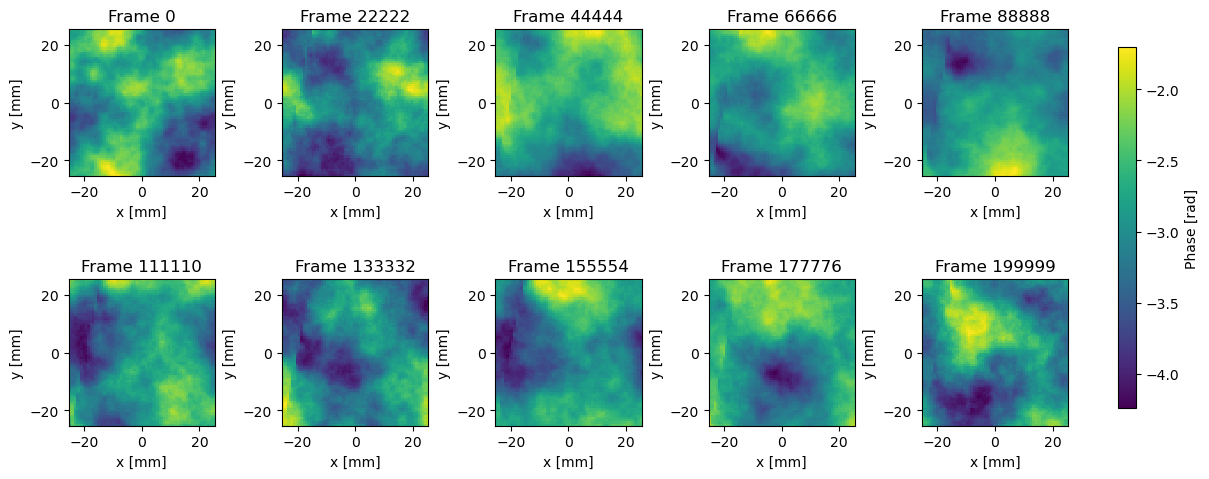

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from numpy.lib.format import open_memmap
from numpy import linalg
from aotools.turbulence.infinitephasescreen import PhaseScreenVonKarman, PhaseScreenKolmogorov


# ---------------- Robust VK screen builder ----------------
def make_vk_screen_robust(nx_size, pupil_diam_m, r0_m, L0_m,
                          random_seed=42, oversize=1.0,
                          max_halves_L0=3, max_oversize_steps=2,
                          verbose=True):

    model = "vonKarman"
    D_sim = pupil_diam_m * oversize

    for oversize_step in range(max_oversize_steps + 1):

        pixel_scale = D_sim / nx_size
        L0_try = L0_m

        for h in range(max_halves_L0 + 1):
            try:
                if verbose:
                    print(f"[VK try] nx={nx_size}, px={pixel_scale:.3e}, r0={r0_m:.3f}, L0={L0_try:.2f}")

                ps = PhaseScreenVonKarman(
                    nx_size=nx_size,
                    pixel_scale=pixel_scale,
                    r0=r0_m,
                    L0=L0_try,
                    random_seed=random_seed
                )
                return ps, pixel_scale, model

            except linalg.LinAlgError as e:
                print("  VK failed:", e)
                if h < max_halves_L0:
                    L0_try *= 0.5
                else:
                    break

        D_sim *= 2.0
        print("  Increasing patch size →", D_sim, "m")

    print("Falling back to Kolmogorov")
    pixel_scale = (pupil_diam_m * oversize) / nx_size

    ps = PhaseScreenKolmogorov(
        nx_size=nx_size,
        pixel_scale=pixel_scale,
        r0=r0_m,
        L0=L0_m,
        random_seed=random_seed
    )

    return ps, pixel_scale, "kolmogorov"


# ---------------- MAIN SCREEN SIM ----------------
def RunSimulation_screen_only(
        wavelength=1550e-9,
        pupil_D=0.0508,
        nx_size=64,
        r0=0.32,
        L0=5.0,
        n_frames=200000,
        oversize=8,
        outname="rx_300m.npy",
        rng_seed=67,
        progress_every=1000,
        verbose=True):

    np.random.seed(rng_seed)

    # ---- build turbulence screen ----
    ps, pixel_scale, model = make_vk_screen_robust(
        nx_size=nx_size,
        pupil_diam_m=pupil_D,
        r0_m=r0,
        L0_m=L0,
        random_seed=rng_seed,
        oversize=oversize,
        verbose=verbose
    )

    if verbose:
        span = nx_size * pixel_scale
        print(f"[screen] model={model}, pixel={pixel_scale:.3e} m, span≈{span:.3f} m")

    # ---- memory-mapped output ----
    out_path = Path(outname).with_suffix(".npy")
    frames = open_memmap(
        str(out_path),
        mode='w+',
        dtype=np.float32,
        shape=(n_frames, nx_size, nx_size)
    )

    # first frame
    frames[0] = np.asarray(ps.scrn, dtype=np.float32)

    # simple frozen-flow
    col_shift_every = 5
    col_shift_pixels = 1

    # ---- generate frames ----
    for i in range(1, n_frames):

        ps.add_row()

        if i % col_shift_every == 0:
            ps.scrn[:] = np.roll(ps.scrn, shift=col_shift_pixels, axis=1)

        frames[i] = np.asarray(ps.scrn, dtype=np.float32)

        if progress_every and i % progress_every == 0:
            print(f"{i}/{n_frames}")

    del frames

    print("Saved →", out_path.resolve())

    # ---- quick montage ----
    data = np.load(out_path, mmap_mode='r')

    fig, axs = plt.subplots(2, 5, figsize=(12, 5), constrained_layout=True)
    sel = np.linspace(0, n_frames-1, 10, dtype=int)

    for ax, idx in zip(axs.ravel(), sel):
        im = ax.imshow(data[idx], origin="lower",
                       extent=[-pupil_D/2*1e3, pupil_D/2*1e3,
                               -pupil_D/2*1e3, pupil_D/2*1e3])
        ax.set_title(f"Frame {idx}")
        ax.set_xlabel("x [mm]")
        ax.set_ylabel("y [mm]")

    fig.colorbar(im, ax=axs.ravel().tolist(), shrink=0.75, label="Phase [rad]")
    plt.show()

    return ps, pixel_scale, model

# === matches your original call (screen-only) ===
ps4, pixel_scale4, model4 = run_screen_simulation(
    pupil_D=0.0508,
    nx_size=64,
    n_frames=200000,
    oversize=8,
    outname="testrx_300m_night_2_long_veryfast.npy",
    rng_seed=67,
    L0=5,
    r0=0.32,
    progress_every=1000,
    show_montage=True,
)